# EDA 2: Distributions, outcomes and home advantage

**Milestone 3, step 5.** Step 4 checked that the data is *correct*; this notebook asks what it
*says*: which patterns a model could learn, and how stable they are over time.

- **Data:** the clean table `data/processed/matches.csv` (1,997 matches, 2011-12 to 2025-26),
  loaded with `src.data.clean.load_clean_matches`.
- **Provisional outcome:** `result` = H / D / A from the **90-minute score** (`home_ft` vs
  `away_ft`). Milestone 4 defines the official target; this notebook only explores.
- **Uncertainty:** where samples are small we report **95% bootstrap confidence intervals**:
  resample the matches with replacement 10,000 times and take the middle 95% of the
  recomputed statistic. If an interval for a difference contains 0, the data cannot rule
  out "no difference".
- **Run:** select the `.venv` kernel and *Run All*, or from the project root:
  `python -m jupyter nbconvert --to notebook --execute --inplace notebooks/02_eda_distributions.ipynb`

In [1]:
# Setup: make the project root importable (the notebook runs from notebooks/).
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import PROCESSED_DATA_DIR, RANDOM_SEED
from src.data.clean import load_clean_matches

pd.set_option("display.width", 160)
df = load_clean_matches(PROCESSED_DATA_DIR / "matches.csv")
df["result"] = np.select([df["home_ft"] > df["away_ft"], df["home_ft"] < df["away_ft"]], ["H", "A"], "D")
df["goal_diff"] = (df["home_ft"] - df["away_ft"]).astype(float)   # home perspective
df["goals"] = (df["home_ft"] + df["away_ft"]).astype(float)
df["era"] = np.select(
    [df["season"] == "2019-20", df["season"] >= "2024-25"],
    ["2019-20 (COVID format)", "2024-26 (36-team league)"],
    "2011-24 (32-team groups)",
)
# True home matches: the listed home side is really at home.
home = df[~df["neutral_venue"] & ~df["played_abroad"]]
print(f"matches: {len(df)} | true home matches: {len(home)} | excluded (neutral or abroad): {len(df) - len(home)}")

matches: 1997 | true home matches: 1959 | excluded (neutral or abroad): 38


In [2]:
# Shared helpers: chart styling, home advantage, bootstrap intervals.
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"   # categorical slots 1-3 (validated)
OUTCOME_COLOURS = {"H": BLUE, "D": ORANGE, "A": AQUA}
rng = np.random.default_rng(RANDOM_SEED)


def new_axes(ncols=1, width=9, height=3.6):
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), facecolor=SURFACE, squeeze=False)
    for ax in axes[0]:
        ax.set_facecolor(SURFACE)
        ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
        ax.tick_params(colors=INK_2, labelsize=9)
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color(GRID)
    return fig, axes[0]


def home_advantage(results: pd.Series) -> float:
    """Home win share minus away win share."""
    return (results == "H").mean() - (results == "A").mean()


def bootstrap_ci(values, stat, n=10_000):
    """95% bootstrap interval of stat(values)."""
    values = np.asarray(values)
    draws = [stat(values[rng.integers(0, len(values), len(values))]) for _ in range(n)]
    return np.percentile(draws, [2.5, 97.5])


def bootstrap_diff_ci(a, b, stat, n=10_000):
    """95% bootstrap interval of stat(a) - stat(b), resampling each group separately."""
    a, b = np.asarray(a), np.asarray(b)
    draws = [stat(a[rng.integers(0, len(a), len(a))]) - stat(b[rng.integers(0, len(b), len(b))]) for _ in range(n)]
    return np.percentile(draws, [2.5, 97.5])

## 1. Goals

In [3]:
goal_counts = pd.DataFrame({
    "home goals": df["home_ft"].clip(upper=6).value_counts().sort_index(),
    "away goals": df["away_ft"].clip(upper=6).value_counts().sort_index(),
}).rename(index={6: "6+"})
goal_share = (goal_counts / len(df)).round(3)
print(f"mean goals per match: home {df['home_ft'].mean():.2f}, away {df['away_ft'].mean():.2f}, total {df['goals'].mean():.2f}")
goal_share

mean goals per match: home 1.71, away 1.32, total 3.03


,home goals,away goals
0,0.219,0.32
1,0.294,0.309
2,0.237,0.201
3,0.136,0.107
4,0.063,0.039
5,0.03,0.013
6+,0.021,0.011


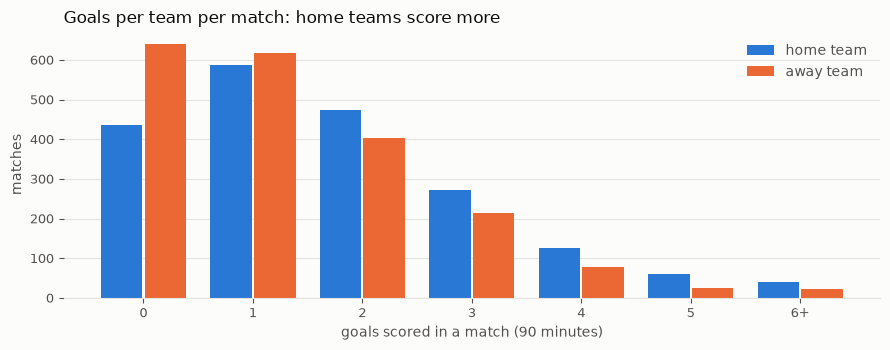

In [4]:
fig, (ax,) = new_axes()
x = np.arange(len(goal_counts))
ax.bar(x - 0.2, goal_counts["home goals"], width=0.38, color=BLUE, label="home team", zorder=2)
ax.bar(x + 0.2, goal_counts["away goals"], width=0.38, color=ORANGE, label="away team", zorder=2)
ax.set_xticks(x, goal_counts.index)
ax.set_xlabel("goals scored in a match (90 minutes)", color=INK_2)
ax.set_ylabel("matches", color=INK_2)
ax.set_title("Goals per team per match: home teams score more", loc="left", color=INK, fontsize=12)
ax.legend(frameon=False, labelcolor=INK_2)
fig.tight_layout()
plt.show()

**What this shows.** Home teams score more: **1.71** goals per match against **1.32** for away teams (3.03 in total). The most common score for a home team is 1 goal (29.4% of matches); for an away team it is 0 (32.0%, against 21.9% for home teams). Goals are small counts with a long right tail: 6 or more goals happen in about 2% of home performances.

**For modelling:** a team's average goals scored and conceded in recent matches is a natural pre-match feature, because goals are the raw material of every result.

In [5]:
per_season = df.groupby("season").agg(matches=("goals", "size"), goals_per_match=("goals", "mean"),
                                      home=("home_ft", "mean"), away=("away_ft", "mean")).round(2)
per_season

,matches,goals_per_match,home,away
season,,,,
2011-12,125,2.75,1.66,1.09
2012-13,125,2.94,1.62,1.32
2013-14,125,2.87,1.62,1.26
2014-15,125,2.87,1.69,1.18
2015-16,125,2.76,1.66,1.1
2016-17,125,3.02,1.81,1.21
2017-18,125,3.21,1.78,1.42
2018-19,125,2.92,1.69,1.23
2019-20,119,3.21,1.67,1.54


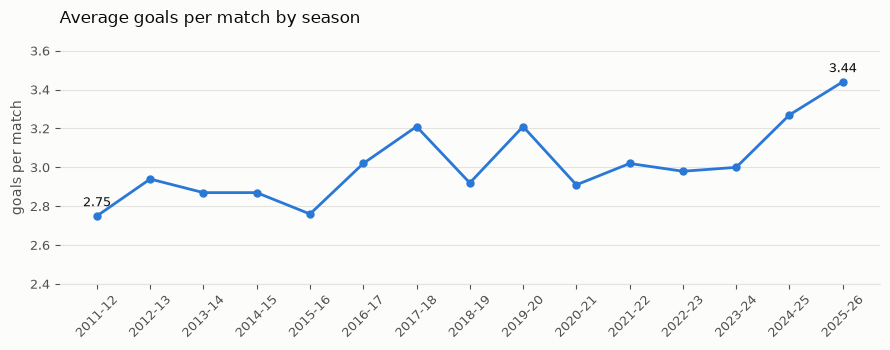

In [6]:
fig, (ax,) = new_axes()
ax.plot(per_season.index, per_season["goals_per_match"], color=BLUE, linewidth=2, marker="o", markersize=5, zorder=3)
ax.set_ylim(2.4, 3.7)
ax.set_ylabel("goals per match", color=INK_2)
ax.set_title("Average goals per match by season", loc="left", color=INK, fontsize=12)
ax.tick_params(axis="x", rotation=45)
for season in (per_season.index[0], per_season.index[-1]):
    value = per_season.loc[season, "goals_per_match"]
    ax.annotate(f"{value:.2f}", (season, value), xytext=(0, 7), textcoords="offset points", ha="center", color=INK, fontsize=9)
fig.tight_layout()
plt.show()

**What this shows.** Goals per match rose from **2.75** (2011-12) to **3.44** (2025-26). The two seasons in the 36-team format are the two highest in the data (3.27 and 3.44), and the rise there is mostly home goals (1.86 and 1.98 per match, against 1.46 to 1.81 in earlier seasons). This data cannot tell us *why* (more uneven match-ups in the new format, tactics, or chance); it only shows that the level moved.

**For modelling: era drift.** A rolling "goals scored" feature means something different at 2.8 goals per match than at 3.4. If we ever normalise such features by the season's average, that average must be computed from matches *before* the one being predicted, or it leaks future information.

## 2. Outcome split: H / D / A

In [7]:
def outcome_table(groups) -> pd.DataFrame:
    table = pd.crosstab(groups, df["result"], normalize="index").reindex(columns=["H", "D", "A"]).round(3)
    table["matches"] = groups.value_counts()
    return table

overall = df["result"].value_counts(normalize=True).reindex(["H", "D", "A"]).round(3)
print("overall:", overall.to_dict(), "| counts:", df["result"].value_counts().reindex(["H", "D", "A"]).to_dict())
by_stage = outcome_table(df["stage"]).reindex(["group", "league", "playoff", "round_of_16", "quarterfinal", "semifinal", "final"])
by_stage

overall: {'H': 0.476, 'D': 0.205, 'A': 0.319} | counts: {'H': 951, 'D': 409, 'A': 637}


result,H,D,A,matches
stage,,,,
group,0.466,0.222,0.312,1248
league,0.514,0.149,0.337,288
playoff,0.438,0.219,0.344,32
round_of_16,0.496,0.171,0.333,240
quarterfinal,0.457,0.224,0.319,116
semifinal,0.569,0.190,0.241,58
final,0.200,0.267,0.533,15


In [8]:
by_era = outcome_table(df["era"])
by_era

result,H,D,A,matches
era,,,,
2011-24 (32-team groups),0.472,0.217,0.311,1500
2019-20 (COVID format),0.437,0.193,0.370,119
2024-26 (36-team league),0.505,0.159,0.336,378


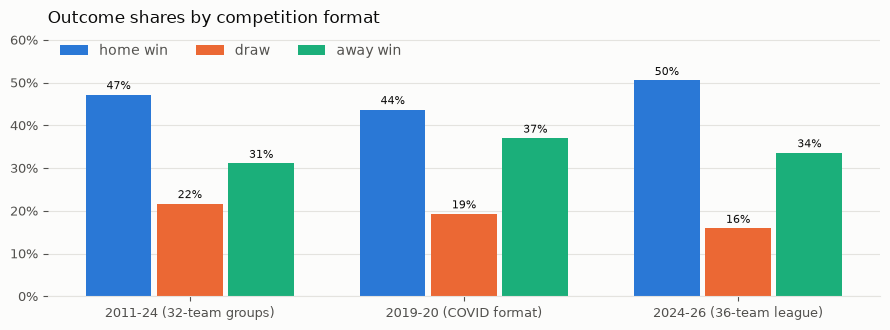

In [9]:
fig, (ax,) = new_axes(height=3.4)
eras = by_era.index.tolist()
x = np.arange(len(eras))
for i, outcome in enumerate(["H", "D", "A"]):
    bars = ax.bar(x + (i - 1) * 0.26, by_era[outcome], width=0.24, color=OUTCOME_COLOURS[outcome],
                  label={"H": "home win", "D": "draw", "A": "away win"}[outcome], zorder=2)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in by_era[outcome]], padding=2, color=INK, fontsize=8)
ax.set_xticks(x, eras)
ax.set_ylim(0, 0.62)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Outcome shares by competition format", loc="left", color=INK, fontsize=12)
ax.legend(frameon=False, labelcolor=INK_2, ncols=3, loc="upper left")
fig.tight_layout()
plt.show()

In [10]:
# The simplest possible "model": always predict the most common class (home win).
def always_home_accuracy(frame: pd.DataFrame) -> float:
    return (frame["result"] == "H").mean()

baseline = pd.Series({
    "all 15 seasons": always_home_accuracy(df),
    "2011-24 (32-team groups)": always_home_accuracy(df[df["era"] == "2011-24 (32-team groups)"]),
    "2024-26 (36-team league)": always_home_accuracy(df[df["era"] == "2024-26 (36-team league)"]),
    "neutral-venue matches only": always_home_accuracy(df[df["neutral_venue"]]),
}).round(3)
print("accuracy of 'always predict H':"); print(baseline.to_string())

# A prior-probability baseline: predict the same H/D/A probabilities for every match.
train_rates = df.loc[df["season"] < "2024-25", "result"].value_counts(normalize=True)
recent = df[df["season"] >= "2024-25"]
log_loss = -np.mean(np.log(recent["result"].map(train_rates)))
print(f"\nH/D/A rates from 2011-24: {train_rates.reindex(['H','D','A']).round(3).to_dict()}")
print(f"log loss of those fixed rates on 2024-26 ({len(recent)} matches): {log_loss:.4f}  (uniform 1/3 each: {np.log(3):.4f})")

accuracy of 'always predict H':
all 15 seasons                0.476
2011-24 (32-team groups)      0.472
2024-26 (36-team league)      0.505
neutral-venue matches only    0.190

H/D/A rates from 2011-24: {'H': 0.469, 'D': 0.216, 'A': 0.315}
log loss of those fixed rates on 2024-26 (378 matches): 1.0138  (uniform 1/3 each: 1.0986)


**What this shows.**
- **Overall:** home win **47.6%**, draw **20.5%**, away win **31.9%** (951 / 409 / 637 matches).
- **By stage:** draws are much rarer in the 36-team league phase (14.9%) than in the old group stage (22.2%). The finals (H 20%, A 53%) are only 15 matches at neutral venues, where "home" just means "listed first", so those shares mean nothing.
- **By era:** the new format has more home wins (50.5% against 47.2%) and fewer draws (15.9% against 21.7%).

**Why base rates become the baseline.** A `DummyClassifier` ignores every feature and learns only the class shares of the training data: `strategy="most_frequent"` always predicts H, and `strategy="prior"` predicts the same probabilities (here about 47 / 22 / 31%) for every match. Any real model must beat it **on the same held-out matches**, or its features add nothing.

**What "always predict H" achieves:** 47.6% accuracy over all 15 seasons, 47.2% in 2011-24, and **50.5% in the 2024-26 format**, which is where we will evaluate. So a model scoring "50% accuracy" on the new format is *no better than always saying home win*. On the 21 truly neutral matches it gets only 19.0%, because there is no home side to favour.

**For probabilities:** the 2011-24 rates (H 46.9%, D 21.6%, A 31.5%) applied to every 2024-26 match give a log loss of **1.0138**, against 1.0986 for a blind 1/3-1/3-1/3 guess. That is the bar a probabilistic model must beat. Note that those old rates over-predict draws for the new format (21.6% against 15.9% observed), which is era drift again.

## 3. Home advantage (true home matches only)

In [11]:
ha_season = home.groupby("season").agg(
    matches=("result", "size"),
    home_win=("result", lambda r: (r == "H").mean()),
    away_win=("result", lambda r: (r == "A").mean()),
    goal_diff=("goal_diff", "mean"),
)
ha_season["home_advantage"] = ha_season["home_win"] - ha_season["away_win"]
# 95% margin of error of (home win share - away win share) for one season's sample size:
# Var = (pH + pA - (pH - pA)^2) / n for a three-outcome (multinomial) share difference.
ha_season["margin_95"] = 1.96 * np.sqrt(
    (ha_season["home_win"] + ha_season["away_win"] - ha_season["home_advantage"] ** 2) / ha_season["matches"])
print(f"overall: home win {(home['result'] == 'H').mean():.3f} - away win {(home['result'] == 'A').mean():.3f} "
      f"= {home_advantage(home['result']):.3f} | mean goal difference {home['goal_diff'].mean():.3f}")
ha_season.round(3)

overall: home win 0.480 - away win 0.314 = 0.166 | mean goal difference 0.413


,matches,home_win,away_win,goal_diff,home_advantage,margin_95
season,,,,,,
2011-12,124,0.500,0.250,0.581,0.250,0.146
2012-13,124,0.468,0.315,0.315,0.153,0.153
2013-14,124,0.500,0.315,0.363,0.185,0.155
2014-15,124,0.508,0.266,0.524,0.242,0.149
2015-16,124,0.540,0.258,0.556,0.282,0.149
2016-17,124,0.444,0.290,0.629,0.153,0.148
2017-18,124,0.444,0.347,0.347,0.097,0.156
2018-19,124,0.460,0.323,0.476,0.137,0.154
2019-20,112,0.455,0.339,0.277,0.116,0.164


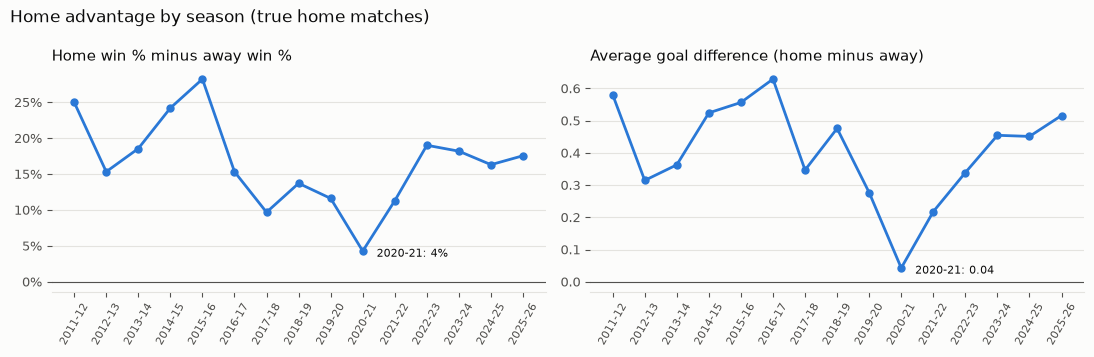

In [12]:
fig, (ax1, ax2) = new_axes(ncols=2, width=11, height=3.6)
for ax, column, title, fmt in [(ax1, "home_advantage", "Home win % minus away win %", "{:.0%}"),
                               (ax2, "goal_diff", "Average goal difference (home minus away)", "{:.2f}")]:
    ax.plot(ha_season.index, ha_season[column], color=BLUE, linewidth=2, marker="o", markersize=5, zorder=3)
    ax.axhline(0, color=INK_2, linewidth=0.8)
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.tick_params(axis="x", rotation=60, labelsize=8)
    value = ha_season.loc["2020-21", column]
    ax.annotate(f"2020-21: {fmt.format(value)}", ("2020-21", value), xytext=(10, -2), textcoords="offset points",
                ha="left", va="center", color=INK, fontsize=8)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.suptitle("Home advantage by season (true home matches)", x=0.01, ha="left", color=INK, fontsize=12)
fig.tight_layout()
plt.show()

**What this shows** (1,959 true home matches; the 21 neutral and 17 played-abroad matches are excluded).
- **Overall:** home teams win **48.0%** and away teams **31.4%**, so home advantage is **+16.6 percentage points**, or **+0.41 goals** per match.
- **Trend:** highest in 2015-16 (+28.2 points) and 2011-12 (+25.0), lowest in **2020-21 (+4.3 points, +0.04 goals)**, and back to +16 to +19 points from 2022-23 onwards.

**How much to trust a single season.** With 112 to 188 matches per season, one season's value has a 95% margin of about **±13 to ±16 percentage points** (`margin_95` column). Most year-to-year wiggles, such as 2015-16 at +28 and 2016-17 at +15, are within that noise. Only 2020-21 stands out, and section 4 tests whether that is about fans.

**Caution.** "Home win % minus away win %" also depends on *which* teams happen to be at home in a sample. Over a whole group stage this balances out (every pair plays once at each ground), but in smaller subsets it does not; section 4 shows that problem in action.

## 4. Natural experiment: with and without fans

In [13]:
# 4a. Naive comparison: all true home matches, split by behind_closed_doors.
closed, fans = home[home["behind_closed_doors"]], home[~home["behind_closed_doors"]]
naive = pd.DataFrame({
    "matches": [len(fans), len(closed)],
    "home_advantage": [home_advantage(fans["result"]), home_advantage(closed["result"])],
    "goal_diff": [fans["goal_diff"].mean(), closed["goal_diff"].mean()],
}, index=["with fans", "behind closed doors"]).round(3)
print(naive.to_string())
diff_ci = bootstrap_diff_ci(fans["result"], closed["result"], home_advantage)
gd_ci = bootstrap_diff_ci(fans["goal_diff"], closed["goal_diff"], np.mean)
print(f"\nfans minus closed, home advantage: {naive.iloc[0, 1] - naive.iloc[1, 1]:+.3f}  95% CI {diff_ci.round(3)}")
print(f"fans minus closed, goal difference: {naive.iloc[0, 2] - naive.iloc[1, 2]:+.3f}  95% CI {gd_ci.round(3)}")
print("\nclosed matches by season:", closed["season"].value_counts().to_dict())

                     matches  home_advantage  goal_diff
with fans               1855           0.167      0.422
behind closed doors      104           0.163      0.260



fans minus closed, home advantage: +0.004  95% CI [-0.172  0.181]
fans minus closed, goal difference: +0.162  95% CI [-0.223  0.566]

closed matches by season: {'2020-21': 89, '2019-20': 6, '2021-22': 4, '2014-15': 3, '2016-17': 1, '2018-19': 1}


In [14]:
# 4b. Is the naive comparison fair? Inside 2020-21, compare closed matches with the
# 28 group matches that had a partial crowd, and look at who hosted those.
season = home[home["season"] == "2020-21"]
for flag, group in season.groupby("behind_closed_doors"):
    label = "behind closed doors" if flag else "partial crowd"
    print(f"2020-21 {label:20} matches={len(group):3} home advantage={home_advantage(group['result']):+.3f} goal diff={group['goal_diff'].mean():+.3f}")
print("partial-crowd hosts:", season.loc[~season["behind_closed_doors"], "home_team"].value_counts().to_dict())

2020-21 partial crowd        matches= 28 home advantage=-0.179 goal diff=-0.286
2020-21 behind closed doors  matches= 89 home advantage=+0.112 goal diff=+0.146
partial-crowd hosts: {'Zenit Saint Petersburg': 3, 'Midtjylland': 3, 'Lokomotiv Moscow': 3, 'Krasnodar': 3, 'Manchester United': 3, 'İstanbul Başakşehir': 2, 'Ferencvárosi TC': 2, 'Dynamo Kyiv': 1, 'Stade Rennais': 1, 'Lazio': 1, 'RB Leipzig': 1, 'Red Bull Salzburg': 1, 'Inter Milan': 1, 'Shakhtar Donetsk': 1, 'Porto': 1, 'Chelsea': 1}


In [15]:
# 4c. Paired estimator. In a group (or a two-legged tie) each pair of clubs plays once at
# each ground. The mean of the two home-perspective goal differences is the pair's home
# advantage: each club's strength appears once with + and once with -, so it cancels.
def home_and_away_pairs(frame: pd.DataFrame) -> pd.DataFrame:
    teams = frame[["home_team", "away_team"]].apply(lambda r: tuple(sorted(r)), axis=1)
    rows = []
    for (season, stage, pair), g in frame.groupby([frame["season"], frame["stage"], teams]):
        if len(g) == 2 and set(g["home_team"]) == set(g["away_team"]):
            rows.append({"season": season, "stage": stage, "pair_home_adv": g["goal_diff"].mean(),
                         "both_closed": g["behind_closed_doors"].all(), "both_fans": (~g["behind_closed_doors"]).all()})
    return pd.DataFrame(rows)

pairs = home_and_away_pairs(home)
both_fans, both_closed = pairs[pairs["both_fans"]], pairs[pairs["both_closed"]]
paired = pd.DataFrame({
    "pairs": [len(both_fans), len(both_closed)],
    "home_adv_goals": [both_fans["pair_home_adv"].mean(), both_closed["pair_home_adv"].mean()],
    "ci_low": [bootstrap_ci(both_fans["pair_home_adv"], np.mean)[0], bootstrap_ci(both_closed["pair_home_adv"], np.mean)[0]],
    "ci_high": [bootstrap_ci(both_fans["pair_home_adv"], np.mean)[1], bootstrap_ci(both_closed["pair_home_adv"], np.mean)[1]],
}, index=["both matches with fans", "both behind closed doors"]).round(3)
print(f"home-and-away pairs: {len(pairs)} (mixed pairs left out: {len(pairs) - len(both_fans) - len(both_closed)})")
print(paired.to_string())
paired_diff = bootstrap_diff_ci(both_fans["pair_home_adv"], both_closed["pair_home_adv"], np.mean)
print(f"\nfans minus closed: {paired.iloc[0, 1] - paired.iloc[1, 1]:+.3f} goals  95% CI {paired_diff.round(3)}")

home-and-away pairs: 834 (mixed pairs left out: 35)
                          pairs  home_adv_goals  ci_low  ci_high
both matches with fans      765           0.418   0.331    0.505
both behind closed doors     34          -0.118  -0.529    0.265



fans minus closed: +0.536 goals  95% CI [0.144 0.95 ]


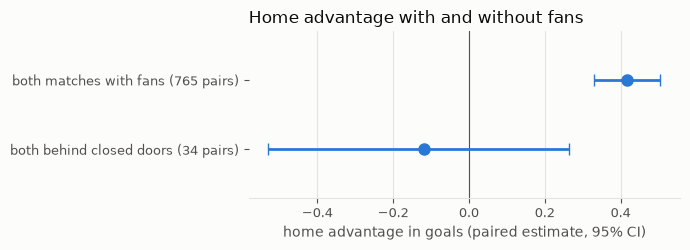

In [16]:
fig, (ax,) = new_axes(width=7, height=2.6)
y = np.arange(len(paired))[::-1]
ax.errorbar(paired["home_adv_goals"], y,
            xerr=[paired["home_adv_goals"] - paired["ci_low"], paired["ci_high"] - paired["home_adv_goals"]],
            fmt="o", color=BLUE, ecolor=BLUE, elinewidth=2, capsize=4, markersize=8, zorder=3)
ax.axvline(0, color=INK_2, linewidth=0.8)
ax.set_yticks(y, [f"{name} ({n} pairs)" for name, n in zip(paired.index, paired["pairs"])])
ax.set_ylim(-0.7, len(paired) - 0.3)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color=GRID, linewidth=0.8, zorder=0)
ax.set_xlabel("home advantage in goals (paired estimate, 95% CI)", color=INK_2)
ax.set_title("Home advantage with and without fans", loc="left", color=INK, fontsize=12)
fig.tight_layout()
plt.show()

**4a. Naive comparison: inconclusive.** Behind closed doors, home advantage was +0.163 (104 true home matches) against +0.167 with fans (1,855). The difference, **+0.004 with a 95% interval of -0.172 to +0.181**, is consistent with no effect, a large effect, or even a reversed one. With 104 matches, this comparison simply cannot tell.

**4b. The naive comparison is also confounded.** In 2020-21 the 28 group matches with a partial crowd had a home advantage of **-0.179**, but look at the hosts: mostly clubs such as Zenit, Midtjylland, Lokomotiv Moscow and Krasnodar (3 each), whose visitors were often stronger. Those matches measure *team strength*, not crowds, and they are mixed into the "with fans" group.

**4c. Paired estimator: strength cancels.** In a group or a two-legged tie, each pair of clubs plays once at each ground. Averaging the two home-perspective goal differences cancels each club's strength exactly, leaving pure home advantage.
- **Both matches with fans:** 765 pairs, **+0.418 goals** (95% CI 0.331 to 0.505).
- **Both behind closed doors:** 34 pairs, **-0.118 goals** (95% CI -0.529 to 0.265).
- **Difference:** **+0.536 goals** (95% CI 0.144 to 0.950). The interval excludes 0.

**Is 118 matches enough? An honest answer.**
- For the naive comparison: **no.**
- The paired analysis gives *evidence* that home advantage shrank without fans, but it rests on only **34 pairs (68 matches)**, and **all 34 are from one season, 2020-21** (24 group pairs, 10 knockout ties). So the comparison is really "2020-21 against every other season". That season also changed schedules, travel and routines, so we cannot separate "no fans" from "everything else about 2020-21".
- I chose the paired method *after* the naive result looked odd. Analysing the same data several ways and reporting the one that "works" inflates false positives (the "garden of forking paths"), so treat this as a well-supported hypothesis, not a proven effect.

**For modelling:** closed-door matches are 118 of 1,997 (5.9%), and the season we will predict has fans everywhere. The flag's real value is to explain why 2020-21 looks unusual, so it does not distort what the model learns about home advantage.

## 5. Two-legged ties: first legs vs second legs

In [17]:
legs = home[home["leg"].isin(["1", "2"])]

def leg_table(frame: pd.DataFrame) -> pd.DataFrame:
    rows = {}
    for leg, g in frame.groupby("leg"):
        shares = g["result"].value_counts(normalize=True).reindex(["H", "D", "A"], fill_value=0)
        rows[f"leg {leg}"] = {"matches": len(g), **shares.round(3).to_dict(),
                              "home_advantage": round(home_advantage(g["result"]), 3),
                              "goal_diff": round(g["goal_diff"].mean(), 3), "goals": round(g["goals"].mean(), 2)}
    return pd.DataFrame(rows).T

print("all two-legged ties:"); print(leg_table(legs).to_string())
for label, stages in [("round of 16 + play-offs (seeded: the stronger side hosts leg 2)", ["round_of_16", "playoff"]),
                      ("quarter- and semi-finals (open draw: leg order is random)", ["quarterfinal", "semifinal"])]:
    sub = legs[legs["stage"].isin(stages)]
    first, second = sub[sub["leg"] == "1"], sub[sub["leg"] == "2"]
    ci = bootstrap_diff_ci(second["result"], first["result"], home_advantage)
    print(f"\n{label}:"); print(leg_table(sub).to_string())
    print(f"leg 2 minus leg 1 home advantage: {home_advantage(second['result']) - home_advantage(first['result']):+.3f}  95% CI {ci.round(3)}")

all two-legged ties:
       matches      H      D      A  home_advantage  goal_diff  goals
leg 1    216.0  0.435  0.204  0.361           0.074      0.088   2.85
leg 2    217.0  0.562  0.189  0.249           0.313      0.876   3.15



round of 16 + play-offs (seeded: the stronger side hosts leg 2):
       matches      H      D      A  home_advantage  goal_diff  goals
leg 1    133.0  0.391  0.203  0.406          -0.015     -0.203   2.91
leg 2    134.0  0.590  0.157  0.254           0.336      1.119   3.19
leg 2 minus leg 1 home advantage: +0.351  95% CI [0.141 0.567]



quarter- and semi-finals (open draw: leg order is random):
       matches      H      D      A  home_advantage  goal_diff  goals
leg 1     83.0  0.506  0.205  0.289           0.217      0.554   2.75
leg 2     83.0  0.518  0.241  0.241           0.277      0.482   3.08
leg 2 minus leg 1 home advantage: +0.060  95% CI [-0.193  0.325]


In [18]:
# Evidence for "the stronger side hosts leg 2" in the round of 16 (2011-24 format):
# compare the group-stage points of the two hosts. (2023-24 has no group letters in the
# source and is left out.)
group = df[(df["stage"] == "group") & df["stage_raw"].str.match(r"^(Group|Gruppe) [A-H]$")]
points = lambda goals_for, goals_against: np.select([goals_for > goals_against, goals_for == goals_against], [3, 1], 0)
group_points = pd.concat([
    pd.DataFrame({"season": group["season"], "team": group["home_team"], "pts": points(group["home_ft"], group["away_ft"])}),
    pd.DataFrame({"season": group["season"], "team": group["away_team"], "pts": points(group["away_ft"], group["home_ft"])}),
]).groupby(["season", "team"])["pts"].sum()
r16 = df[(df["stage"] == "round_of_16") & df["season"].isin(group["season"].unique())]
gaps = pd.Series([
    group_points[(t.season.iloc[0], t.loc[t.leg == "2", "home_team"].iloc[0])]
    - group_points[(t.season.iloc[0], t.loc[t.leg == "1", "home_team"].iloc[0])]
    for _, t in r16.groupby("tie_id")
])
print(f"round-of-16 ties checked: {len(gaps)} | leg-2 host had more group points: {(gaps > 0).sum()}, "
      f"equal: {(gaps == 0).sum()}, fewer: {(gaps < 0).sum()} | mean gap: {gaps.mean():+.2f} points")

round-of-16 ties checked: 96 | leg-2 host had more group points: 80, equal: 5, fewer: 11 | mean gap: +3.29 points


**What this shows.**
- **Naive:** second-leg hosts look far stronger at home: home advantage +0.313 against +0.074 in first legs.
- **Seeded rounds (round of 16, play-offs):** UEFA's draw rules make the better-placed side host the second leg, and our data confirms it: in 96 round-of-16 ties (2011-12 to 2022-23), the leg-2 host collected **more group points in 80**, the same in 5, and fewer in 11, **+3.3 points on average**. (A group winner can still have fewer points than a runner-up from another group, hence the 11.) Here leg 2 minus leg 1 is **+0.351** (95% CI 0.141 to 0.567), but that is mostly *who* is at home.
- **Open-draw rounds (quarter- and semi-finals):** leg order is random, so team strength is balanced. The difference shrinks to **+0.060** (95% CI -0.193 to +0.325): **no evidence of a genuine second-leg advantage** in 83 ties.
- **Goals:** second legs have more goals (3.15 against 2.85 overall; 3.08 against 2.75 in open draws). A plausible reason is that the side trailing on aggregate must attack, but this data does not prove it.

**For modelling:** the first-leg score is known before the second leg kicks off, so "aggregate score going into leg 2" is a legitimate pre-match feature. The leg number alone mostly stands in for team strength, which the form features should capture directly.

## 6. What this means for feature engineering

**Patterns that suggest useful features**

| Finding | Feature idea (Milestone 5) |
|---|---|
| Both confounded comparisons (sections 4 and 5) turned out to be about **team strength** | Strength and form features come first: rolling points, goals scored and conceded over the last `FORM_WINDOW` matches, possibly a rating such as Elo |
| Home advantage is **+16.6 points / +0.41 goals** in true home matches, and absent on neutral ground | Use `neutral_venue` and `played_abroad` so the model does not credit a "home" side that is not at home |
| Second legs: the first-leg result is known before kickoff | Aggregate score going into leg 2 |
| Draws: 22.2% in group stages but 14.9% in the league phase | A format indicator, or train and evaluate with the format in mind |

**Findings that warn about era drift**

- **The prediction era is small:** the 36-team format is only 378 matches (19% of the data), yet it is the format of 2026-27. A chronological split will put most of it in validation and test, which is right, but the training data will mostly come from the old format.
- **Base rates moved:** home wins 47.2% -> 50.5%, draws 21.7% -> 15.9%. A model trained on old seasons will tend to over-predict draws for the new format; calibration (Milestone 8) must be checked on new-format matches.
- **Goal levels moved:** 2.75 -> 3.44 goals per match. Goal-based features shift in scale over time; any normalisation must use only earlier matches.
- **2020-21 is atypical:** home advantage near zero, most matches behind closed doors.

**Leakage reminders:** everything above that is measured *during* a match (goals, half-time scores, attendance on the day) may only enter features through matches played *before* the one being predicted.